Implementación de PINN para la solución de EDP usando Jax y una arquitectura tipo MLP

In [1]:
import jax
import jax.numpy as jnp

# Función escalar simple
def f(x):
    return jnp.sin(jnp.cos(x**2))

In [2]:
# Primera derivada f'(x)
df = jax.grad(f)

# Segunda derivada f''(x)
d2f = jax.grad(df)

x_val = 2.0
print("f(x):", f(x_val))
print("f'(x):", df(x_val))
print("f''(x):", d2f(x_val))

f(x): -0.608083
f'(x): 2.4032216
f''(x): 15.076648


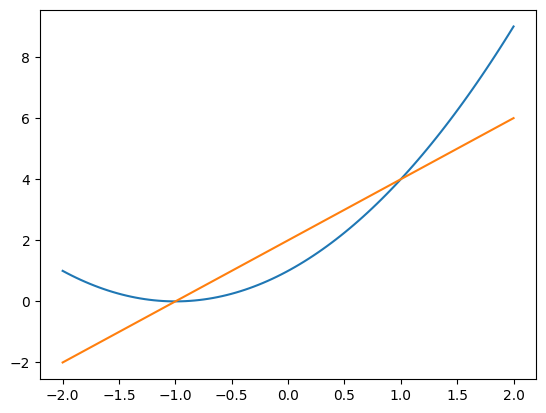

In [3]:
def f(x):
    return x**2 + 2.0 * x + 1.0

# Evaluación sobre un array
x_arr = jnp.linspace(-2.0, 2.0, 100)

y_arr = f(x_arr)
df_arr = jax.vmap(jax.grad(f))(x_arr)


# print(y_arr)
# print(df_arr)


import matplotlib.pyplot as plt

plt.plot(x_arr, y_arr)
plt.plot(x_arr, df_arr)
plt.show()

Creación de PINN para la solución de la ecuación de calor en una dimensión. Se aborda el problema de una barra de longitud $L$. Con las condiciones $U|_{x=0} = T = U|_{x=L}$ y $U|_{t=0} = T_0$

$$ \frac{\partial U}{ \partial t} = \alpha \frac{\partial ^2 U}{\partial x^2}$$

La función de coste $J(\theta)$ de nuestro sistema se implementa a partir del residuo

$$r_{\theta}(x,t) = \frac{\partial u_{\theta}}{ \partial t} - \alpha \frac{\partial^2 u_{\theta}}{\partial x^2} $$

definiendose como la suma ponderada del error cuadratico medio (MSE) de cada una de las contribuciones

$$ J(\theta) = w_r L_r(\theta) +  w_0 L_0(\theta) + w_b L_b(\theta) $$

donde 

$$L_r(\theta) = \frac{1}{N_r} \sum_{i=1}^{N_r} |r_\theta(x^{(i)}, t^{(i)})|^2  $$

$N_r$ es el número total de puntos en el espacio posicion-tiempo.

$$ L_0(\theta) = \frac{1}{N_0} \sum_{i=1}^{N_0} |u_\theta(x^{(i)}, 0) - T_0|^2$$

$N_0$ siendo el número de puntos considerados para la situación inicial

$$ L_b(\theta) = \frac{1}{2 N_b} \sum_{i=1}^{N_b} \left(|u_\theta(0, t^{(i)}) - T|^2 + |u_\theta(L, t^{(i)}) - T|^2\right)$$

siendo $N_b$ el número de puntos sobre la frontera (Corresponde al número de pasos temporales)

Vamos a construir neuronas cuya función de activación $f(z) = \tanh(z)$ donde $z = \theta_x x + \theta_t t + \theta_b$

Recordemos que en esta aproximación la salida de la red neuronal $u_{\theta}(x,t)$ es la temperatura $U(x,t)$, por tanto:

$$ (x,t) \xrightarrow{\text{forward}} U(x,t) $$

In [4]:
# 1. Definición del forward pass de la red u_theta(x, t)
def forward(params, x, t):
    h = jnp.array([x, t])
    for W, b in params[:-1]:
        z = jnp.dot(W, h) + b
        h = jnp.tanh(z)
    W_last, b_last = params[-1]
    return (jnp.dot(W_last, h) + b_last)[0]

Note que `params` es un array de tuplas de la forma

$$ \text{params} = [(W_1,b_1), (W_2,b_2), ... , (W_L,b_L)] $$

por tanto el forward implica que:

$$ h_i^{(l)} \rightarrow h_i^{(l+1)} = \tanh( W_{ij}^{(l+1)} h_j^{(l)} + b_i^{(l+1)}) $$

donde $h^{(0)} = (x,t)$ y $ u_{\theta} = W_{j}^{(L)} \cdot h_j^{(L-1)} + b^{(L)} $ es la salida de la red, particularmente el step $L$ corresponde a la capa de salida.

In [5]:

# 2. Operador del residuo diferencial en un solo punto (x, t)
def residual_point(params, x, t, alpha):
    # u_t = du/dt (argnums=2)
    u_t = jax.grad(forward, argnums=2)(params, x, t)
    
    # u_xx = d^2u/dx^2 (argnums=1 dos veces)
    u_x = jax.grad(forward, argnums=1)
    u_xx = jax.grad(u_x, argnums=1)(params, x, t)
    
    return u_t - alpha * u_xx

# 3. Vectorización sobre batches con jax.vmap
u_batch = jax.vmap(forward, in_axes=(None, 0, 0))
residual_batch = jax.vmap(residual_point, in_axes=(None, 0, 0, None))

Definimos el operador vectorial a través de la función `jax.vmap(f, in_axes)` donde el argumento `in_axes` me permite definir cuales son mis variables vectoriales y cuales son parametros fijos respecto a las entradas del `def`

In [6]:
# 4. Función de pérdida compuesta
def loss_fn(params, data, alpha, T_fria, T_caliente, weights=(1.0, 1.0, 1.0)):
    w_r, w_0, w_b = weights
    
    # Datos de colocación
    x_r, t_r = data['residual']
    x_0, t_0 = data['initial']
    t_b = data['boundary_t']
    L = data['L']
    
    # 1. Pérdida del residuo interior
    res = residual_batch(params, x_r, t_r, alpha)
    loss_r = jnp.mean(res**2)
    
    # 2. Pérdida de condición inicial: u(x, 0) = T_fria
    u_0_pred = u_batch(params, x_0, t_0)
    loss_0 = jnp.mean((u_0_pred - T_fria)**2)
    
    # 3. Pérdida de frontera: u(0, t) = T_caliente, u(L, t) = T_caliente
    u_b_left = u_batch(params, jnp.zeros_like(t_b), t_b)
    u_b_right = u_batch(params, jnp.full_like(t_b, L), t_b)
    loss_b = 0.5 * (jnp.mean((u_b_left - T_caliente)**2) + jnp.mean((u_b_right - T_caliente)**2))
    
    return w_r * loss_r + w_0 * loss_0 + w_b * loss_b


Se calculo la función de perdida usando las condiciones de frontera como ligadura física al problema.

In [7]:

# 5. Paso de optimización (compilado con JIT)
@jax.jit
def train_step(params, data, alpha, T_fria, T_caliente, lr):
    loss, grads = jax.value_and_grad(loss_fn)(params, data, alpha, T_fria, T_caliente)
    # Descenso de gradiente estándar (SGD): theta = theta - lr * grad
    new_params = [
        (W - lr * dW, b - lr * db)
        for (W, b), (dW, db) in zip(params, grads)
    ]
    return new_params, loss

In [8]:
def init_network_params(layer_sizes, key):
    """
    Inicializa una lista de tuplas (W, b) usando Xavier/Glorot.
    layer_sizes: lista con las dimensiones de entrada, ocultas y salida.
    """
    keys = jax.random.split(key, len(layer_sizes) - 1)
    params = []
    
    for k, (n_in, n_out) in zip(keys, zip(layer_sizes[:-1], layer_sizes[1:])):
        w_key, _ = jax.random.split(k)
        # Escala de Glorot
        std_glorot = jnp.sqrt(2.0 / (n_in + n_out))
        W = jax.random.normal(w_key, (n_out, n_in)) * std_glorot
        b = jnp.zeros((n_out,))
        params.append((W, b))
        
    return params

# Ejemplo de uso:
key = jax.random.PRNGKey(0)
layers = [2, 32, 32, 32, 1]
params = init_network_params(layers, key)

In [9]:
for i, (W, b) in enumerate(params):
    print(f"Capa {i+1}: W shape = {W.shape}, b shape = {b.shape}")

Capa 1: W shape = (32, 2), b shape = (32,)
Capa 2: W shape = (32, 32), b shape = (32,)
Capa 3: W shape = (32, 32), b shape = (32,)
Capa 4: W shape = (1, 32), b shape = (1,)


Generación de `data`

In [ ]:
def generar_datos_entrenamiento(key, L=1.0, t_max=5.0, N_r=2000, N_0=200, N_b=200):
    k1, k2, k3, k4 = jax.random.split(key, 4)
    
    # 1. Puntos interiores para el residuo: x en (0, L), t en (0, t_max)
    x_r = jax.random.uniform(k1, shape=(N_r,), minval=0.0, maxval=L)
    t_r = jax.random.uniform(k2, shape=(N_r,), minval=0.0, maxval=t_max)
    
    # 2. Puntos para la condición inicial: x en (0, L) evitando la discontinuidad en las esquinas, t = 0 fijo
    eps = 1e-3 * L
    x_0 = jax.random.uniform(k3, shape=(N_0,), minval=eps, maxval=L - eps)
    t_0 = jnp.zeros(N_0)
    
    # 3. Puntos temporales para las fronteras (x=0 y x=L): t en (0, t_max)
    t_b = jax.random.uniform(k4, shape=(N_b,), minval=0.0, maxval=t_max)
    
    data = {
        'L': L,
        't_max': t_max,
        'residual': (x_r, t_r),
        'initial': (x_0, t_0),
        'boundary_t': t_b
    }
    return data

data = generar_datos_entrenamiento(key, L=1.0, t_max=5.0)

{'L': 1.0, 't_max': 5.0, 'residual': (Array([0.8423141 , 0.18237865, 0.2271781 , ..., 0.5800003 , 0.59222317,
       0.93336046], dtype=float32), Array([0.0364691 , 0.10445595, 2.9071326 , ..., 1.244297  , 4.4801874 ,
       0.406695  ], dtype=float32)), 'initial': (Array([0.9016446 , 0.91146827, 0.34136555, 0.22065093, 0.64808   ,
       0.50752014, 0.71676993, 0.22618985, 0.59083664, 0.06906205,
       0.18091382, 0.96038955, 0.16927502, 0.33345163, 0.7919472 ,
       0.8840972 , 0.45717716, 0.18398209, 0.9147525 , 0.551657  ,
       0.27802476, 0.3226487 , 0.2857525 , 0.6085744 , 0.4344631 ,
       0.95119905, 0.23835035, 0.9781166 , 0.83235013, 0.04352174,
       0.15575814, 0.37424055, 0.17718789, 0.27450785, 0.95657337,
       0.8394885 , 0.5557664 , 0.670552  , 0.76334167, 0.36330795,
       0.4113812 , 0.13500106, 0.97250044, 0.7850549 , 0.7871236 ,
       0.82621235, 0.8950706 , 0.3735561 , 0.2841012 , 0.5623621 ,
       0.34491685, 0.5831291 , 0.2628455 , 0.81956375, 0.270717

Iniciando entrenamiento con SGD...
Época     1 | Pérdida total: 4.1857e+00
Época  1000 | Pérdida total: 1.6469e-01
Época  2000 | Pérdida total: 1.5498e-01
Época  3000 | Pérdida total: 1.2105e-01
Época  4000 | Pérdida total: 8.8265e-02
Época  5000 | Pérdida total: 7.1686e-02
Época  6000 | Pérdida total: 6.5453e-02
Época  7000 | Pérdida total: 6.2475e-02
Época  8000 | Pérdida total: 6.0146e-02
Época  9000 | Pérdida total: 5.8382e-02
Época 10000 | Pérdida total: 5.7170e-02


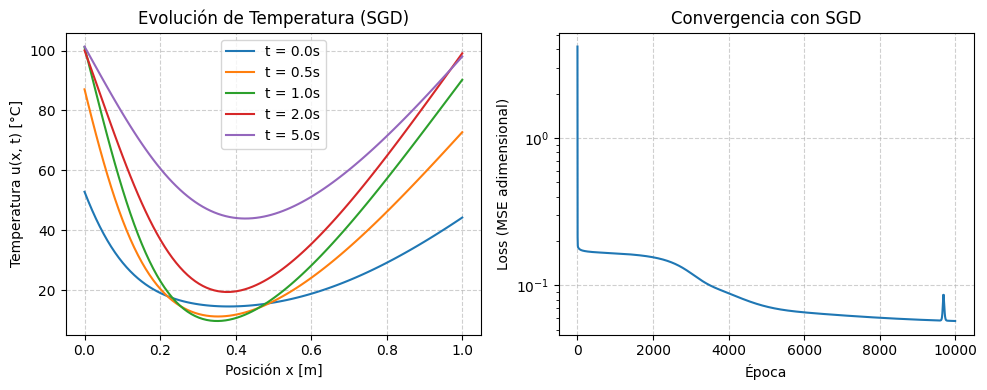

In [11]:
# Parámetros físicos del problema
alpha = 0.01          # Difusividad térmica [m^2/s]
T_fria = 20.0         # Temperatura inicial de la barra [°C]
T_caliente = 100.0    # Temperatura en ambos extremos (x=0 y x=L) [°C]

# Temperaturas adimensionalizadas en [0, 1] para evitar saturación de tanh
T_fria_norm = 0.0
T_caliente_norm = 1.0

# Hiperparámetros de SGD
epochs = 10000        # Se suelen requerir más iteraciones con SGD
lr = 1e-2             # Tasa de aprendizaje (adecuada para salida normalizada en [0, 1])

# Reinicializamos parámetros para garantizar punto de partida limpio
params = init_network_params(layers, key)
loss_history = []

print("Iniciando entrenamiento con SGD...")
for epoch in range(1, epochs + 1):
    params, loss_val = train_step(
        params, data, alpha, T_fria_norm, T_caliente_norm, lr
    )
    loss_history.append(float(loss_val))
    
    if epoch % 1000 == 0 or epoch == 1:
        print(f"Época {epoch:5d} | Pérdida total: {loss_val:.4e}")

# ==============================================================================
# 6. EVALUACIÓN Y VISUALIZACIÓN
# ==============================================================================
L = float(data['L'])
nx = 100
x_eval = jnp.linspace(0, L, nx)
t_evals = [0.0, 0.5, 1.0, 2.0, 5.0]

plt.figure(figsize=(10, 4))

# Gráfica de perfiles u(x, t)
plt.subplot(1, 2, 1)
for t_i in t_evals:
    t_arr = jnp.full_like(x_eval, t_i)
    u_pred_norm = u_batch(params, x_eval, t_arr)
    u_pred = T_fria + u_pred_norm * (T_caliente - T_fria)
    plt.plot(x_eval, u_pred, label=f't = {t_i}s')
plt.xlabel('Posición x [m]')
plt.ylabel('Temperatura u(x, t) [°C]')
plt.title('Evolución de Temperatura (SGD)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

# Gráfica de convergencia de la función de coste
plt.subplot(1, 2, 2)
plt.semilogy(loss_history, color='tab:blue')
plt.xlabel('Época')
plt.ylabel('Loss (MSE adimensional)')
plt.title('Convergencia con SGD')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

La siguiente celda integra todo lo definidio en la sección anterior incorporando ademas un optimizador ADAM con el fin de mejorar los resultados obtenidos

Iniciando entrenamiento...
Época     1 | Pérdida total: 4.1857e+00
Época   500 | Pérdida total: 1.5872e-01
Época  1000 | Pérdida total: 7.8553e-02
Época  1500 | Pérdida total: 5.8064e-02
Época  2000 | Pérdida total: 4.9983e-02
Época  2500 | Pérdida total: 3.2072e-02
Época  3000 | Pérdida total: 1.9552e-02
Época  3500 | Pérdida total: 1.3671e-02
Época  4000 | Pérdida total: 1.0372e-02
Época  4500 | Pérdida total: 8.0924e-03
Época  5000 | Pérdida total: 6.6346e-03


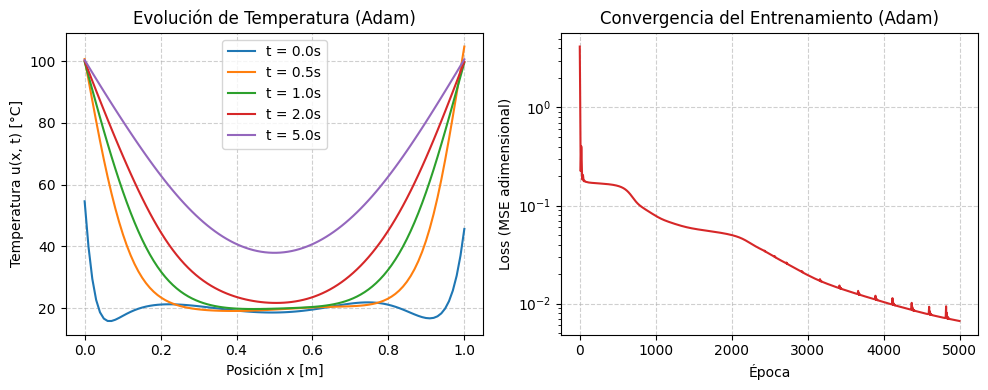

In [12]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

# ==============================================================================
# 1. ARQUITECTURA DE LA RED NEURONAL (MLP)
# ==============================================================================
def forward(params, x, t):
    """Evalúa la red en un punto escalar (x, t)."""
    h = jnp.array([x, t])
    for W, b in params[:-1]:
        z = jnp.dot(W, h) + b
        h = jnp.tanh(z)
    W_last, b_last = params[-1]
    return (jnp.dot(W_last, h) + b_last)[0]

# ==============================================================================
# 2. OPERADORES DIFERENCIALES Y VECTORIZACIÓN
# ==============================================================================
def residual_point(params, x, t, alpha):
    """Calcula el residuo r(x, t) = u_t - alpha * u_xx en un punto escalar."""
    # u_t: derivada temporal (argnums=2)
    u_t = jax.grad(forward, argnums=2)(params, x, t)
    
    # u_xx: segunda derivada espacial (argnums=1)
    u_x_fn = jax.grad(forward, argnums=1)
    u_xx = jax.grad(u_x_fn, argnums=1)(params, x, t)
    
    return u_t - alpha * u_xx

# Vectorización sobre lotes (batches) de puntos
u_batch = jax.vmap(forward, in_axes=(None, 0, 0))
residual_batch = jax.vmap(residual_point, in_axes=(None, 0, 0, None))

# ==============================================================================
# 3. FUNCIÓN DE COSTE (LOSS FUNCTION)
# ==============================================================================
def loss_fn(params, data, alpha, T_fria, T_caliente, weights=(1.0, 1.0, 1.0)):
    w_r, w_0, w_b = weights
    
    x_r, t_r = data['residual']
    x_0, t_0 = data['initial']
    t_b = data['boundary_t']
    L = data['L']
    
    # 1. Residuo de la EDP en el interior
    res = residual_batch(params, x_r, t_r, alpha)
    loss_r = jnp.mean(res**2)
    
    # 2. Condición inicial: u(x, 0) = T_fria
    u_0_pred = u_batch(params, x_0, t_0)
    loss_0 = jnp.mean((u_0_pred - T_fria)**2)
    
    # 3. Condiciones de frontera:
    #    Borde izquierdo (x = 0): caliente (T_caliente)
    #    Borde derecho (x = L): caliente (T_caliente)
    u_b_left = u_batch(params, jnp.zeros_like(t_b), t_b)
    u_b_right = u_batch(params, jnp.full_like(t_b, L), t_b)
    loss_b = 0.5 * (jnp.mean((u_b_left - T_caliente)**2) + jnp.mean((u_b_right - T_caliente)**2))
    
    return w_r * loss_r + w_0 * loss_0 + w_b * loss_b

# ==============================================================================
# 4. OPTIMIZADOR ADAM (Implementado directamente en JAX puro)
# ==============================================================================
def init_adam_state(params):
    m = jax.tree_util.tree_map(jnp.zeros_like, params)
    v = jax.tree_util.tree_map(jnp.zeros_like, params)
    return {'m': m, 'v': v, 'step': 0}

@jax.jit
def train_step_adam(params, opt_state, data, alpha, T_fria, T_caliente, lr=1e-3, 
                    beta1=0.9, beta2=0.999, eps=1e-8):
    loss, grads = jax.value_and_grad(loss_fn)(params, data, alpha, T_fria, T_caliente)
    
    step = opt_state['step'] + 1
    # Actualización de momentos de Adam
    m = jax.tree_util.tree_map(lambda m_prev, g: beta1 * m_prev + (1.0 - beta1) * g, opt_state['m'], grads)
    v = jax.tree_util.tree_map(lambda v_prev, g: beta2 * v_prev + (1.0 - beta2) * (g**2), opt_state['v'], grads)
    
    # Corrección de sesgo
    m_hat = jax.tree_util.tree_map(lambda mi: mi / (1.0 - beta1**step), m)
    v_hat = jax.tree_util.tree_map(lambda vi: vi / (1.0 - beta2**step), v)
    
    # Actualización de pesos
    new_params = jax.tree_util.tree_map(
        lambda p, mh, vh: p - lr * mh / (jnp.sqrt(vh) + eps),
        params, m_hat, v_hat
    )
    
    new_opt_state = {'m': m, 'v': v, 'step': step}
    return new_params, new_opt_state, loss

# ==============================================================================
# 5. BUCLE DE ENTRENAMIENTO
# ==============================================================================
# Parámetros físicos del problema
alpha = 0.01          # Difusividad térmica [m^2/s]
T_fria = 20.0         # Temperatura inicial de la barra [°C]
T_caliente = 100.0    # Temperatura en ambos extremos (x=0 y x=L) [°C]

# Temperaturas adimensionalizadas en [0, 1] para estabilidad numérica
T_fria_norm = 0.0
T_caliente_norm = 1.0

epochs = 5000         # Número de iteraciones
lr = 1e-3             # Tasa de aprendizaje

# Reinicializamos `params` para comparar en igualdad de condiciones con SGD
params = init_network_params(layers, key)
opt_state = init_adam_state(params)

loss_history = []

print("Iniciando entrenamiento...")
for epoch in range(1, epochs + 1):
    params, opt_state, loss_val = train_step_adam(
        params, opt_state, data, alpha, T_fria_norm, T_caliente_norm, lr=lr
    )
    loss_history.append(float(loss_val))
    
    if epoch % 500 == 0 or epoch == 1:
        print(f"Época {epoch:5d} | Pérdida total: {loss_val:.4e}")

# ==============================================================================
# 6. EVALUACIÓN Y VISUALIZACIÓN DE PERFILES TÉRMICOS
# ==============================================================================
L = data['L']
nx, nt = 100, 5
x_eval = jnp.linspace(0, L, nx)
t_evals = [0.0, 0.5, 1.0, 2.0, 5.0]  # Tiempos representativos

plt.figure(figsize=(10, 4))

# Gráfica de perfiles u(x, t)
plt.subplot(1, 2, 1)
for t_i in t_evals:
    t_arr = jnp.full_like(x_eval, t_i)
    u_pred_norm = u_batch(params, x_eval, t_arr)
    u_pred = T_fria + u_pred_norm * (T_caliente - T_fria)
    plt.plot(x_eval, u_pred, label=f't = {t_i}s')
plt.xlabel('Posición x [m]')
plt.ylabel('Temperatura u(x, t) [°C]')
plt.title('Evolución de Temperatura (Adam)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

# Gráfica de convergencia de la función de coste
plt.subplot(1, 2, 2)
plt.semilogy(loss_history, color='tab:red')
plt.xlabel('Época')
plt.ylabel('Loss (MSE adimensional)')
plt.title('Convergencia del Entrenamiento (Adam)')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

La solución analítica para este problema viene dado por la siguiente serie:

$$ U(x,t) = T_{\text{max}} - \frac{4(T_{\text{max}} - T_{\text{min}})}{\pi} \sum_{k_1}^{\infty} \frac{1}{2k-1} \sin{\left(  \frac{2k-1}{L} \pi x \right)}  \exp \left(  -\alpha \frac{(2k-1)^2 \pi^2}{L^2} t \right) $$

con esta expresión en mente comparemos la solución obtenida mediante la PINN con función de activación $\tanh(z)$, esto a través del error absoluto entre ambas soluciones.

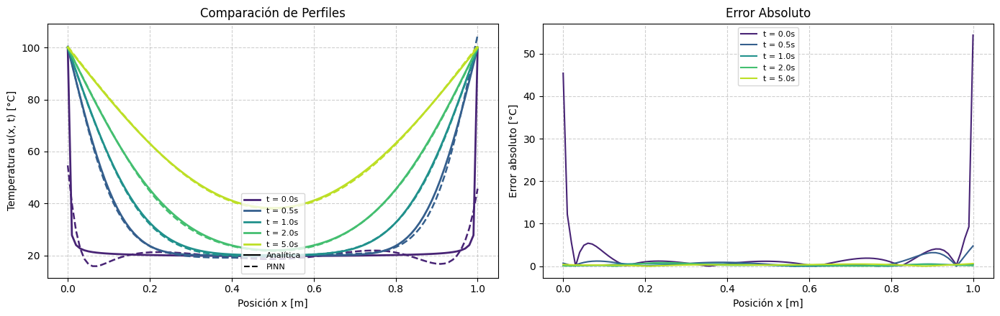

In [13]:
import jax.numpy as jnp
import matplotlib.pyplot as plt

# ==============================================================================
# FUNCIÓN DE LA SOLUCIÓN ANALÍTICA (SERIE DE FOURIER)
# ==============================================================================
def u_analitica(x, t, L, alpha, T_min, T_max, n_terminos=100):
    delta_T = T_max - T_min
    k = jnp.arange(1, n_terminos + 1)
    n = 2 * k - 1  # Armónicos impares: 1, 3, 5, ...

    # Dimensiones para broadcasting: x -> (N, 1), n -> (1, n_terminos)
    x_col = x[:, None]
    n_row = n[None, :]

    seno = jnp.sin(n_row * jnp.pi * x_col / L)
    exponencial = jnp.exp(-alpha * (n_row * jnp.pi / L) ** 2 * t)
    coeficientes = 1.0 / n_row

    suma = jnp.sum(coeficientes * seno * exponencial, axis=1)
    return T_max - (4.0 * delta_T / jnp.pi) * suma


# ==============================================================================
# 6. EVALUACIÓN Y COMPARACIÓN: ANALÍTICA vs PINN
# ==============================================================================
L = float(data['L'])
nx = 100
x_eval = jnp.linspace(0.0, L, nx)
t_evals = [0.0, 0.5, 1.0, 2.0, 5.0]

plt.figure(figsize=(14, 4.5))

# ------------------------------------------------------------------------------
# Subplot 1: Comparación directa de perfiles de temperatura
# ------------------------------------------------------------------------------
plt.subplot(1, 2, 1)
colores = plt.cm.viridis(jnp.linspace(0.1, 0.9, len(t_evals)))

for t_i, color in zip(t_evals, colores):
    # 1. Solución Analítica exacta
    u_exact = u_analitica(x_eval, t_i, L=L, alpha=alpha, T_min=T_fria, T_max=T_caliente)
    plt.plot(x_eval, u_exact, color=color, linewidth=2.0, label=f't = {t_i}s')

    # 2. Predicción de la PINN (desnormalizada)
    t_arr = jnp.full_like(x_eval, t_i)
    u_pred_norm = u_batch(params, x_eval, t_arr)
    u_pred = T_fria + u_pred_norm * (T_caliente - T_fria)
    plt.plot(x_eval, u_pred, '--', color=color, linewidth=1.8)

# Dummy plots para la leyenda del estilo de línea
plt.plot([], [], 'k-', label='Analítica')
plt.plot([], [], 'k--', label='PINN')

plt.xlabel('Posición x [m]')
plt.ylabel('Temperatura u(x, t) [°C]')
plt.title('Comparación de Perfiles')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower center', fontsize=8)

# ------------------------------------------------------------------------------
# Subplot 2: Error puntual absoluto |u_PINN - u_Analitica|
# ------------------------------------------------------------------------------
plt.subplot(1, 2, 2)
for t_i, color in zip(t_evals, colores):
    u_exact = u_analitica(x_eval, t_i, L=L, alpha=alpha, T_min=T_fria, T_max=T_caliente)
    t_arr = jnp.full_like(x_eval, t_i)
    u_pred_norm = u_batch(params, x_eval, t_arr)
    u_pred = T_fria + u_pred_norm * (T_caliente - T_fria)
    
    error_abs = jnp.abs(u_pred - u_exact)
    plt.plot(x_eval, error_abs, color=color, linewidth=1.5, label=f't = {t_i}s')

plt.xlabel('Posición x [m]')
plt.ylabel('Error absoluto [°C]')
plt.title('Error Absoluto')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(fontsize=8)


plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

De la comparación es evidente notar que el error se concentra en las soluciones de tiempos bajos. En este caso es facíl ver que se debe a la discontinuidad que se plantea al tener dichas condiciones de frontera y con las condiciones iniciales. 

Ahora creemos una clase solver para la solución de EDP 1-D. Para esto, inspirados en la solución ya propuesta y con ayuda de Gemini 4.0 Argon definimos una calse denominada `PINN`. El objetivo de esta clase es construir un Solver basado en la arquitectura de una Neural Network el cual permita flexibilidad a la hora de resolver una EDP 1-D con dependencia temporal de hasta segundo orden. La calse recibe en su constructor los siguientes parámetros:

1. `topologia`
2. `activation_list`
3. `condiciones_frontera`
4. `condiciones_iniciales`
5. `pde_fn=None`
6. `t_max=1.0`
7. `weights=(1.0, 1.0, 1.0)`
8. `normalizar=True`
9. `seed=0`

La `topologia` es una lista de enteros con la cantidad de neuronas en cada capa. Ahora `activation_list` corresponde a una lista de strings que permite designar la función de activación implementada en cada capa de nuestra red, en caso de que el len de la lista de activación sea $L-2$ con $L$ la longitud de topología, se asume que la salida no pasara por ninguna función de activación, en caso de ser $L-1$ se aplicara la activación correspondiente en la última capa. 


In [39]:
import jax
import jax.numpy as jnp
from functools import partial


class PINN:
    """
    Clase flexible para resolver EDPs 1D espacio-temporales (x, t) mediante PINNs en JAX.
    """

    # Catálogo de funciones de activación soportadas por nombre (str)
    ACTIVATIONS = {
        "tanh": jnp.tanh,
        "sin": jnp.sin,
        "cos": jnp.cos,
        "sigmoid": jax.nn.sigmoid,
        "relu": jax.nn.relu,
        "gelu": jax.nn.gelu,
        "swish": jax.nn.swish,
        "silu": jax.nn.silu,
        "softplus": jax.nn.softplus,
        "elu": jax.nn.elu,
        "linear": lambda z: z,
        "identity": lambda z: z,
    }

    def __init__(
        self,
        topologia,
        activation_list,
        condiciones_frontera,
        condiciones_iniciales,
        pde_fn=None,
        t_max=1.0,
        weights=(1.0, 1.0, 1.0),
        normalizar=True,
        seed=0,
    ):
        """
        Parámetros:
        -----------
        topologia : list[int]
            Número de neuronas por capa, ej. [2, 32, 32, 32, 1].
        activation_list : list[str]
            Nombres de las funciones de activación para cada capa oculta
            (longitud = len(topologia) - 2) o incluyendo la capa de salida
            (longitud = len(topologia) - 1).
        condiciones_frontera : list[tuple]
            Lista de tuplas (x_extremo, valor) o (x_extremo, valor, tipo).
            - `x_extremo`: float con la posición del borde (ej. 0.0 y L).
            - `valor`: constante (float) o función callable f(t).
            - `tipo` (opcional): 'dirichlet' (por defecto) o 'neumann' (du/dx).
        condiciones_iniciales : float | callable | dict | tuple
            Condición en t = 0:
            - float: temperatura/estado inicial constante u(x, 0) = T_0.
            - callable: función f(x) tal que u(x, 0) = f(x).
            - dict/tuple: {'u0': f(x), 'ut0': g(x)} para EDPs de 2do orden en t (ej. onda).
        pde_fn : callable, opcional
            Función que define el residuo de la EDP: pde_fn(derivs, x, t) -> residual.
            `derivs` es un diccionario con {'u', 'u_t', 'u_tt', 'u_x', 'u_xx'}.
            Si es None, usa por defecto la ecuación de calor: u_t - 0.01 * u_xx = 0.
        """
        self.topologia = list(topologia)
        self.condiciones_frontera = condiciones_frontera
        self.condiciones_iniciales = condiciones_iniciales
        self.t_max = float(t_max)
        self.weights = weights
        self.normalizar = normalizar

        # Validación y resolución de funciones de activación por capa
        n_transiciones = len(self.topologia) - 1
        if len(activation_list) == n_transiciones - 1:
            act_names = list(activation_list) + ["linear"]
        elif len(activation_list) == n_transiciones:
            act_names = list(activation_list)
        else:
            raise ValueError(
                f"activation_list debe tener {n_transiciones - 1} (capas ocultas) "
                f"o {n_transiciones} (incluyendo salida) elementos."
            )

        self.activation_names = [name.lower() for name in act_names]
        self.activations = []
        for name in self.activation_names:
            if name not in self.ACTIVATIONS:
                raise ValueError(f"Activación '{name}' no reconocida. Opciones: {list(self.ACTIVATIONS.keys())}")
            self.activations.append(self.ACTIVATIONS[name])

        # EDP por defecto: Ecuación de calor 1D con alpha = 0.01
        if pde_fn is None:
            self.pde_fn = lambda d, x, t: d["u_t"] - 0.01 * d["u_xx"]
        else:
            self.pde_fn = pde_fn

        # Dominio espacial deducido de las condiciones de frontera
        xs_frontera = [ float(bc[0]) for bc in self.condiciones_frontera ]
        self.x_min = min(xs_frontera)
        self.x_max = max(xs_frontera)

        # Escala de normalización automática para la salida u(x, t)
        self._configurar_escala()

        # Vectorización de operadores con jax.vmap
        self._u_batch = jax.vmap(self._forward_fisico, in_axes=(None, 0, 0))
        self._u_x_batch = jax.vmap(jax.grad(self._forward_fisico, argnums=1), in_axes=(None, 0, 0))
        self._u_t_batch = jax.vmap(jax.grad(self._forward_fisico, argnums=2), in_axes=(None, 0, 0))
        self._res_batch = jax.vmap(self._residual_point, in_axes=(None, 0, 0))

        # Inicialización de parámetros y estado del optimizador
        self.params = None
        self.opt_state = None
        self.loss_history = []
        self.inicializar(seed=seed)

    def _configurar_escala(self):
        """Determina u_offset y u_scale a partir de CI y CF para trabajar internamente en [0, 1]."""
        if not self.normalizar:
            self.u_offset = 0.0
            self.u_scale = 1.0
            return

        valores_ref = []
        for bc in self.condiciones_frontera:
            val = bc[1]
            if isinstance(val, (int, float)):
                valores_ref.append(float(val))

        ci = self.condiciones_iniciales
        if isinstance(ci, (int, float)):
            valores_ref.append(float(ci))
        elif isinstance(ci, dict) and isinstance(ci.get("u0"), (int, float)):
            valores_ref.append(float(ci["u0"]))

        if len(valores_ref) >= 2 and max(valores_ref) > min(valores_ref):
            self.u_offset = min(valores_ref)
            self.u_scale = max(valores_ref) - min(valores_ref)
        else:
            self.u_offset = 0.0
            self.u_scale = 1.0

    # ==========================================================================
    # 1. MÉTODO INICIALIZAR
    # ==========================================================================
    def inicializar(self, seed=0, N_r=2000, N_0=200, N_b=200):
        """
        Inicializa los pesos de la red (Glorot/Xavier), el estado del optimizador
        y genera los puntos de colocación en el dominio (x, t).
        """
        key = jax.random.PRNGKey(seed)
        k_params, k_data = jax.random.split(key)

        keys = jax.random.split(k_params, len(self.topologia) - 1)
        params = []
        for k, (n_in, n_out) in zip(keys, zip(self.topologia[:-1], self.topologia[1:])):
            w_key, _ = jax.random.split(k)
            std_glorot = jnp.sqrt(2.0 / (n_in + n_out))
            W = jax.random.normal(w_key, (n_out, n_in)) * std_glorot
            b = jnp.zeros((n_out,))
            params.append((W, b))

        self.params = params
        self.opt_state = {
            "m": jax.tree_util.tree_map(jnp.zeros_like, self.params),
            "v": jax.tree_util.tree_map(jnp.zeros_like, self.params),
            "step": 0,
        }
        self.loss_history = []
        self.data = self._generar_datos(k_data, N_r=N_r, N_0=N_0, N_b=N_b)
        return self.params

    def _generar_datos(self, key, N_r=2000, N_0=200, N_b=200):
        k1, k2, k3, k4 = jax.random.split(key, 4)
        L_dom = self.x_max - self.x_min
        eps = 1e-3 * L_dom

        x_r = jax.random.uniform(k1, shape=(N_r,), minval=self.x_min, maxval=self.x_max)
        t_r = jax.random.uniform(k2, shape=(N_r,), minval=0.0, maxval=self.t_max)

        x_0 = jax.random.uniform(k3, shape=(N_0,), minval=self.x_min + eps, maxval=self.x_max - eps)
        t_0 = jnp.zeros(N_0)

        t_b = jax.random.uniform(k4, shape=(N_b,), minval=0.0, maxval=self.t_max)
        return {"residual": (x_r, t_r), "initial": (x_0, t_0), "boundary_t": t_b}

    # ==========================================================================
    # ARQUITECTURA FORWARD Y OPERADORES DIFERENCIALES
    # ==========================================================================
    def _forward_norm(self, params, x, t):
        """Paso hacia adelante con función de activación propia por capa."""
        h = jnp.array([x, t])
        for (W, b), act_fn in zip(params, self.activations):
            z = jnp.dot(W, h) + b
            h = act_fn(z)
        return h[0]

    def _forward_fisico(self, params, x, t):
        """Devuelve u(x, t) en unidades físicas originales."""
        return self.u_offset + self.u_scale * self._forward_norm(params, x, t)

    def _residual_point(self, params, x, t):
        """Evalúa las derivadas en (x, t) y las pasa a `self.pde_fn`."""
        u_fn = self._forward_fisico
        u_x_fn = jax.grad(u_fn, argnums=1)
        u_t_fn = jax.grad(u_fn, argnums=2)

        derivs = {
            "u": u_fn(params, x, t),
            "u_x": u_x_fn(params, x, t),
            "u_xx": jax.grad(u_x_fn, argnums=1)(params, x, t),
            "u_t": u_t_fn(params, x, t),
            "u_tt": jax.grad(u_t_fn, argnums=2)(params, x, t),
        }
        return self.pde_fn(derivs, x, t) / self.u_scale

    def _evaluar_objetivo(self, especificacion, pts):
        """Convierte una constante o función callable en un array de valores objetivo."""
        if callable(especificacion):
            return especificacion(pts)
        return jnp.full_like(pts, float(especificacion))

    def loss_fn(self, params, data):
        w_r, w_0, w_b = self.weights
        x_r, t_r = data["residual"]
        x_0, t_0 = data["initial"]
        t_b = data["boundary_t"]

        # 1. Pérdida del residuo de la EDP
        res = self._res_batch(params, x_r, t_r)
        loss_r = jnp.mean(res ** 2)

        # 2. Pérdida de condiciones iniciales (soporta u(x,0) y opcionalmente u_t(x,0))
        ci = self.condiciones_iniciales
        if isinstance(ci, dict):
            u0_target = self._evaluar_objetivo(ci["u0"], x_0)
            u0_pred = self._u_batch(params, x_0, t_0)
            loss_0 = jnp.mean(((u0_pred - u0_target) / self.u_scale) ** 2)
            if "ut0" in ci and ci["ut0"] is not None:
                ut0_target = self._evaluar_objetivo(ci["ut0"], x_0)
                ut0_pred = self._u_t_batch(params, x_0, t_0)
                loss_0 = loss_0 + jnp.mean(((ut0_pred - ut0_target) / self.u_scale) ** 2)
        elif isinstance(ci, (tuple, list)):
            u0_target = self._evaluar_objetivo(ci[0], x_0)
            u0_pred = self._u_batch(params, x_0, t_0)
            loss_0 = jnp.mean(((u0_pred - u0_target) / self.u_scale) ** 2)
            if len(ci) > 1 and ci[1] is not None:
                ut0_target = self._evaluar_objetivo(ci[1], x_0)
                ut0_pred = self._u_t_batch(params, x_0, t_0)
                loss_0 = loss_0 + jnp.mean(((ut0_pred - ut0_target) / self.u_scale) ** 2)
        else:
            u0_target = self._evaluar_objetivo(ci, x_0)
            u0_pred = self._u_batch(params, x_0, t_0)
            loss_0 = jnp.mean(((u0_pred - u0_target) / self.u_scale) ** 2)

        # 3. Pérdida de condiciones de frontera (Dirichlet o Neumann en cada extremo)
        loss_b_terms = []
        for bc in self.condiciones_frontera:
            x_extremo = float(bc[0])
            valor_bc = bc[1]
            tipo_bc = bc[2].lower() if len(bc) > 2 else "dirichlet"

            x_b = jnp.full_like(t_b, x_extremo)
            target_b = self._evaluar_objetivo(valor_bc, t_b)

            if tipo_bc == "dirichlet":
                pred_b = self._u_batch(params, x_b, t_b)
            elif tipo_bc == "neumann":
                pred_b = self._u_x_batch(params, x_b, t_b)
            else:
                raise ValueError(f"Tipo de condición de frontera '{tipo_bc}' no soportado.")

            loss_b_terms.append(jnp.mean(((pred_b - target_b) / self.u_scale) ** 2))

        loss_b = jnp.mean(jnp.stack(loss_b_terms))
        return w_r * loss_r + w_0 * loss_0 + w_b * loss_b

    # ==========================================================================
    # 2. MÉTODO ENTRENAR
    # ==========================================================================
    @partial(jax.jit, static_argnums=(0,))
    def _step_adam(self, params, opt_state, data, lr, beta1=0.9, beta2=0.999, eps=1e-8):
        loss, grads = jax.value_and_grad(self.loss_fn)(params, data)
        step = opt_state["step"] + 1
        m = jax.tree_util.tree_map(lambda mp, g: beta1 * mp + (1.0 - beta1) * g, opt_state["m"], grads)
        v = jax.tree_util.tree_map(lambda vp, g: beta2 * vp + (1.0 - beta2) * (g ** 2), opt_state["v"], grads)
        m_hat = jax.tree_util.tree_map(lambda mi: mi / (1.0 - beta1 ** step), m)
        v_hat = jax.tree_util.tree_map(lambda vi: vi / (1.0 - beta2 ** step), v)
        new_params = jax.tree_util.tree_map(lambda p, mh, vh: p - lr * mh / (jnp.sqrt(vh) + eps), params, m_hat, v_hat)
        return new_params, {"m": m, "v": v, "step": step}, loss

    @partial(jax.jit, static_argnums=(0,))
    def _step_sgd(self, params, data, lr):
        loss, grads = jax.value_and_grad(self.loss_fn)(params, data)
        new_params = jax.tree_util.tree_map(lambda p, g: p - lr * g, params, grads)
        return new_params, loss

    def entrenar(self, epochs=5000, lr=1e-3, optimizador="adam", print_every=500):
        """
        Entrena la PINN utilizando 'adam' o 'sgd'.
        """
        opt = optimizador.lower()
        for epoch in range(1, epochs + 1):
            if opt == "adam":
                self.params, self.opt_state, loss_val = self._step_adam(
                    self.params, self.opt_state, self.data, lr
                )
            elif opt == "sgd":
                self.params, loss_val = self._step_sgd(self.params, self.data, lr)
            else:
                raise ValueError("Optimizador no soportado. Use 'adam' o 'sgd'.")

            self.loss_history.append(float(loss_val))
            if print_every and (epoch % print_every == 0 or epoch == 1):
                print(f"Época {epoch:5d} | Pérdida ({opt.upper()}): {loss_val:.4e}")

        return self.loss_history

    # ==========================================================================
    # 3. MÉTODO PREDECIR
    # ==========================================================================
    def predecir(self, x, t):
        """
        Evalúa la solución física u(x, t).
        Acepta escalares o arrays 1D para x y t.
        """
        x_arr = jnp.atleast_1d(jnp.asarray(x, dtype=jnp.float32))
        t_arr = jnp.atleast_1d(jnp.asarray(t, dtype=jnp.float32))
        if x_arr.shape != t_arr.shape:
            x_arr, t_arr = jnp.broadcast_arrays(x_arr, t_arr)
        return self._u_batch(self.params, x_arr, t_arr)


# ==============================================================================
# EJEMPLO DE USO DE LA CLASE PINN
# ==============================================================================
# 1. Definición flexible de la EDP (Ecuación de calor 1D con alpha = 0.01)
alpha_val = 0.01
ecuacion_calor = lambda derivs, x, t: derivs["u_t"] - alpha_val * derivs["u_xx"]

# 2. Instanciación con activaciones por capa, fronteras e iniciales
modelo_pinn = PINN(
    topologia=[2, 32, 32, 32, 1],
    activation_list=["tanh", "tanh", "tanh"],
    condiciones_frontera=[(0.0, 100.0), (1.0, 100.0)],
    condiciones_iniciales=20.0,
    pde_fn=ecuacion_calor,
    t_max=5.0,
)

# 3. Entrenamiento y predicción
historial = modelo_pinn.entrenar(epochs=5000, lr=1e-3, optimizador="adam", print_every=1000)
x_test = jnp.linspace(0.0, 1.0, 100)
u_t1 = modelo_pinn.predecir(x_test, 1.0)


Época     1 | Pérdida (ADAM): 5.0539e-01
Época  1000 | Pérdida (ADAM): 4.2224e-02
Época  2000 | Pérdida (ADAM): 1.4446e-02
Época  3000 | Pérdida (ADAM): 7.6111e-03
Época  4000 | Pérdida (ADAM): 3.9446e-03
Época  5000 | Pérdida (ADAM): 1.9050e-03


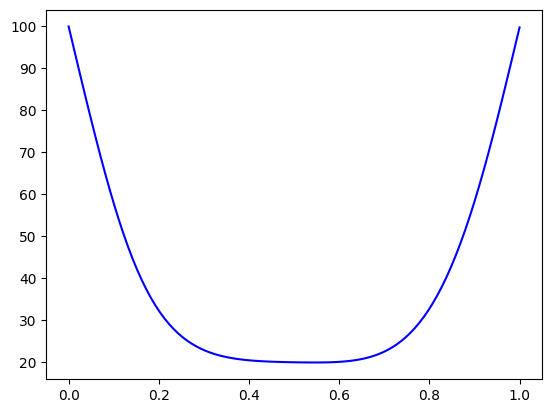

In [41]:
plt.plot(x_test, u_t1, label='Predicción PINN', color='blue')
plt.show()

### Propuesta para la solución de la ecuación de Schrödinger 1-D con el método de PINNS:

Debido al caracter complejo de la ecuación se me ocurre en primer instancia predecir dos valores, es decir separar la función de onda en sus dos componentes, real e imaginario:

$$ \psi (x,t) = u(x,t) + i w(x,t) $$

así pues tendriamos realmente dos funciones residuo, una correspondiente a la parte real y la otra a la parte immaginaria de la ecuación

$$ r_{\theta}^{(R)} = \hbar \partial_t u_{\theta} + \frac{\hbar^2}{2m} \partial_x^2 w_{\theta} - V(x) w_{\theta}  $$

y 

$$ r_{\theta}^{(I)} = \hbar \partial_t w_{\theta} - \frac{\hbar^2}{2m} \partial_x^2 u_{\theta} + V(x) u_{\theta}  $$

Como vemos los residuos están acoplados. Por ende la perdida se dividira en sus dos componentes, real e imaginario. Esto en realidad no es mas que considerar un residuo complejo de la forma $r_{\theta} = r_{\theta}^{(R)} + i r_{\theta}^{(I)}$ de modo que la función de perdida $L_r(\theta)$ seguira igual

$$L_r(\theta) = \frac{1}{N_r} \sum_{k=1}^{N_r} |r_\theta(x^{(k)}, t^{(k)})|^2  = \frac{1}{N_r} \sum_{k=1}^{N_r} |r_{\theta}^{(R,k)} + i r_{\theta}^{(I,k)}|^2 =  \frac{1}{N_r} \sum_{k=1}^{N_r} \left[ \left(r_{\theta}^{(R,k)}\right)^2 +  \left(r_{\theta}^{(I,k)} \right)^2 \right] $$

como este metodo tiene un soporte compacto, es decir está algo límitado al dominio donde se trabaje, unicamente tendremos en cuenta pozos de potencial y la solución al interior de estos pozos, es decir, $\psi$ se anulara siempre en los extremos. 

$$ L_b(\theta) = \frac{1}{2 N_b} \sum_{i=1}^{N_b} \left(|\psi_\theta(0, t^{(i)})|^2 + |\psi_\theta(L, t^{(i)})|^2\right)$$

donde $|\psi|^2 = \psi \psi^* = u^2 + w^2$

Supondremos además que conoces con totalidad el estado inicial del sistema (Probablemente alguna combinación lineal de los autoestados del Hamiltoniano), por tanto la perdida se podrá evaluar para cada función por separado, es decir

$$ L_0(\theta) = \frac{1}{N_0} \sum_{i=1}^{N_0} \left( |u_\theta(x^{(i)}, 0) - f(x^{(i)})|^2 + |w_\theta(x^{(i)}, 0) - g(x^{(i)})|^2\right)$$

siendo $\psi_0(x) = f(x) + i g(x)$.

Si empleamos unicamente estas componentes para nuestra función de perdida, corremos con el riesgo de fallar en una de las hipotesis fundamentales sobre la función de onda, siendo esta la conservación de la probabilidad. Para evitar esto impondremos ademas la condición 

$$ \int |\psi(x,t)|^2 dx = 1 $$

en otras palabras, se propondra un componente extra para la función de perdida $L_{n}$ tal que:

$$ L_{n}(\theta) = \frac{1}{N_n}\sum_{i=1}^{N_n}\left( \int \psi_\theta (x,t_i) ^2 dx - 1  \right) ^ 2 $$

La función de perdida total sera entonces $L(\theta)$

$$ L(\theta) = w_r L_r(\theta) + w_b L_b(\theta) + w_0 L_0(\theta) + w_n L_n(\theta) $$

La arquitectura de la red debe entonces entrenarse de modo que hayan dos salidas, la correspondiente a $u_{\theta}(x,t)$ y la correspondiente a $w_{\theta}(x,t)$, idealmente ambas corresponden entonces a las soluciones de la ecuación de onda la cual es de la forma

$$ i\hbar \frac{\partial \psi}{\partial t}(x,t) = - \frac{\hbar^2}{2m} \frac{\partial ^ 2 \psi}{\partial x^2 }(x,t) + V(x)\psi(x,t)$$



Para ejemplificar la solución propongas un pozo en el intervalo $[0,L]$ el cual experimenta un potencial lineal $V(x) = \frac{k^2}{2}x $ con $k$ una constante. 

1. Definimos el Forward, el cúal debe ser identico en forma al caso anterior, la diferencia debe radicar en que el return corresponde a un vector (2,). Por simplicidad usaremos nuevamente la activación $\tanh(z)$

In [21]:
hbar = 1 #1.054571817e-34  # Constante de Planck reducida [J·s]
m = 1.0  # Masa de la partícula [kg]

In [22]:

def forward(params, x, t):
    h = jnp.array([x, t])
    for W, b in params[:-1]:
        z = jnp.dot(W, h) + b
        h = jnp.tanh(z)
    W_last, b_last = params[-1]
    return (jnp.dot(W_last, h) + b_last)

forward_batch = jax.vmap(forward, in_axes=(None, 0, 0))

Entonces `params[-1] = (W_L, b_L)` debe ser tal que $W_L \in M^{N_{L-1} \times 2}$ y $b_l \in \mathbb{R}^2 $ 

In [23]:
# Funciones auxiliares escalares
u_fn = lambda params, x, t: forward(params, x, t)[0]
w_fn = lambda params, x, t: forward(params, x, t)[1]

def residual_point_schrodinger(params, x, t, k):
    u, w = forward(params, x, t)

    u_t = jax.grad(u_fn, argnums=2)(params, x, t)
    u_xx = jax.grad(jax.grad(u_fn, argnums=1), argnums=1)(params, x, t)

    w_t = jax.grad(w_fn, argnums=2)(params, x, t)
    w_xx = jax.grad(jax.grad(w_fn, argnums=1), argnums=1)(params, x, t)

    V_x = k/2 * x**2  # Potencial lineal V(x) = k * x
    r_R = hbar * w_t - (0.5 * (hbar ** 2) / m) * u_xx + V_x * u
    r_I = hbar * u_t + (0.5 * (hbar ** 2) / m) * w_xx - V_x * w
    return r_R, r_I

residual_batch_schrodinger = jax.vmap(residual_point_schrodinger, in_axes=(None, 0, 0, None))

La condición inicial estará dada por dos autoestados del pozo en ausencia de potencial

$$ \psi(x,0) = \sqrt{\frac{1}{L}} \left[  \sin\left(\frac{\pi x}{L}\right) +  \sin\left( \frac{2 \pi x}{L}\right) \right] $$

es decir la parte imaginaria $g(x) = 0$ mientras que la parte real $f(x) = \psi(x,0)$.

In [25]:
def f_inicial(x, L=1.0):
    return jnp.sqrt(1.0 / L) * (jnp.sin(jnp.pi * x / L) + jnp.sin(2.0 * jnp.pi * x / L))

def g_inicial(x, L=1.0):
    return jnp.zeros_like(x)

def loss_schrodinger(params, data, k, weights=(1.0, 20.0, 10.0, 10.0)):

    w_r, w_0, w_b, w_n = weights
    x_r, t_r = data["residual"]
    x_0, t_0 = data["initial"]
    t_b = data["boundary_t"]
    L = data["L"]

    r_R, r_I = residual_batch_schrodinger(params, x_r, t_r, k)
    loss_r = jnp.mean(r_R ** 2 + r_I ** 2)

    psi_0_pred = forward_batch(params, x_0, t_0)
    u_0_pred, w_0_pred = psi_0_pred[:, 0], psi_0_pred[:, 1]
    loss_0 = jnp.mean((u_0_pred - f_inicial(x_0, L)) ** 2 + (w_0_pred - g_inicial(x_0, L)) ** 2)

    psi_left = forward_batch(params, jnp.zeros_like(t_b), t_b)
    psi_right = forward_batch(params, jnp.full_like(t_b, L), t_b)
    loss_b = 0.5 * (jnp.mean(jnp.sum(psi_left ** 2, axis=1)) + jnp.mean(jnp.sum(psi_right ** 2, axis=1)))

    # 4. Pérdida de conservación de la norma: \int_0^L |\psi(x, t)|^2 dx = 1
    x_int = jnp.linspace(0.0, 1.0, 100) * L

    def integral_norma_en_t(t_i):
        t_vec = jnp.full_like(x_int, t_i)
        psi_t = forward_batch(params, x_int, t_vec)
        densidad = jnp.sum(psi_t ** 2, axis=1)  # |psi|^2 = u^2 + w^2
        return jnp.trapezoid(densidad, x_int)

    integral = jax.vmap(integral_norma_en_t)(t_b)
    loss_n = jnp.mean((integral - 1.0) ** 2)

    return w_r * loss_r + w_0 * loss_0 + w_b * loss_b + w_n * loss_n



Para el entrenamiento volvemos a usar Adam

In [26]:
@jax.jit
def train_step_schrodinger(params, opt_state, data, k, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8):
    loss, grads = jax.value_and_grad(loss_schrodinger)(params, data, k)
    step = opt_state["step"] + 1
    m_opt = jax.tree_util.tree_map(lambda mp, g: beta1 * mp + (1.0 - beta1) * g, opt_state["m"], grads)
    v_opt = jax.tree_util.tree_map(lambda vp, g: beta2 * vp + (1.0 - beta2) * (g ** 2), opt_state["v"], grads)
    m_hat = jax.tree_util.tree_map(lambda mi: mi / (1.0 - beta1 ** step), m_opt)
    v_hat = jax.tree_util.tree_map(lambda vi: vi / (1.0 - beta2 ** step), v_opt)
    new_params = jax.tree_util.tree_map(lambda p, mh, vh: p - lr * mh / (jnp.sqrt(vh) + eps), params, m_hat, v_hat)
    return new_params, {"m": m_opt, "v": v_opt, "step": step}, loss


Inicialización y entrenamiento de la red. Note que reutilice la función `init_network_params()` que utiliza el algoritmo de Xavier/Glorot. Los datos de entrenamiento siguen una distribución uniforme empleando nuevmanete la función `generar_datos_entrenamiento`.

In [27]:
key_qm = jax.random.PRNGKey(42)
layers_qm = [2, 64, 64, 64, 2]
params_qm = init_network_params(layers_qm, key_qm)
opt_state_qm = init_adam_state(params_qm)

L_pozo = 1.0
t_max_qm = 2.0
k_potencial = 5.0  # Pendiente del potencial lineal V(x) = k * x
data_qm = generar_datos_entrenamiento(key_qm, L=L_pozo, t_max=t_max_qm, N_r=3000, N_0=300, N_b=300)

# 5. Entrenamiento con Adam
epochs_qm = 5000
lr_qm = 1e-3
loss_hist_qm = []

print("Iniciando entrenamiento de la PINN para Schrödinger 1D...")
for epoch in range(1, epochs_qm + 1):
    params_qm, opt_state_qm, loss_val = train_step_schrodinger(
        params_qm, opt_state_qm, data_qm, k_potencial, lr=lr_qm
    )
    loss_hist_qm.append(float(loss_val))
    if epoch % 1000 == 0 or epoch == 1:
        print(f"Época {epoch:5d} | Pérdida total: {loss_val:.4e}")

Iniciando entrenamiento de la PINN para Schrödinger 1D...
Época     1 | Pérdida total: 2.8145e+01
Época  1000 | Pérdida total: 2.5137e+00
Época  2000 | Pérdida total: 6.6883e-01
Época  3000 | Pérdida total: 3.5066e-01
Época  4000 | Pérdida total: 2.2261e-01
Época  5000 | Pérdida total: 1.6333e-01


Visualización de los resultados

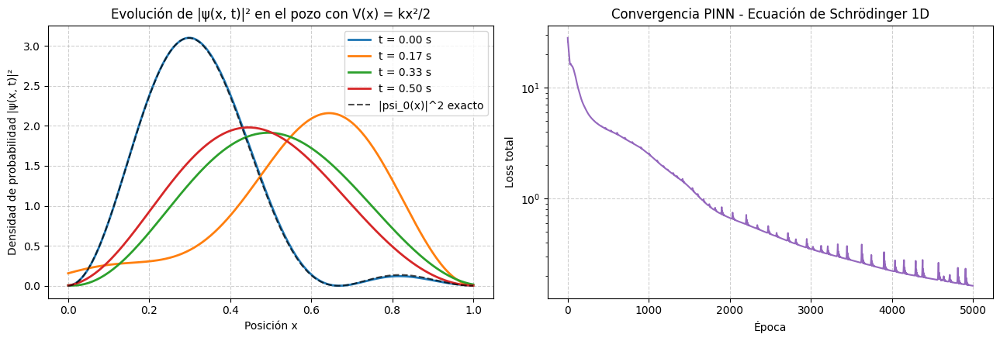

In [34]:
x_plot = jnp.linspace(0.0, L_pozo, 200)
t_iempos = [0.0, 0.1, 0.25, 0.5]

t_iempos = jnp.linspace(0.0, 0.5, 4)

plt.figure(figsize=(13, 4.5))

plt.subplot(1, 2, 1)
for t_i in t_iempos:
    t_vec = jnp.full_like(x_plot, t_i)
    psi_pred = forward_batch(params_qm, x_plot, t_vec)
    prob_density = psi_pred[:, 0] ** 2 + psi_pred[:, 1] ** 2
    plt.plot(x_plot, prob_density, linewidth=2.0, label=f"t = {t_i:.2f} s")

plt.plot(x_plot, f_inicial(x_plot, L_pozo) ** 2, "k--", alpha=0.7, label="|psi_0(x)|^2 exacto")
plt.xlabel("Posición x")
plt.ylabel("Densidad de probabilidad |ψ(x, t)|²")
plt.title("Evolución de |ψ(x, t)|² en el pozo con V(x) = kx²/2")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()

plt.subplot(1, 2, 2)
plt.semilogy(loss_hist_qm, color="tab:purple")
plt.xlabel("Época")
plt.ylabel("Loss total")
plt.title("Convergencia PINN - Ecuación de Schrödinger 1D")
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

In [35]:
import matplotlib.animation as animation
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML

# 1. Malla espacial y temporal para la animación
n_frames = 80
x_plot = jnp.linspace(0.0, L_pozo, 200)
t_frames = jnp.linspace(0.0, 1.0, n_frames)

# 2. Precomputar todas las predicciones
# Matriz de densidades calculadas por adelantado
densities = []
for t_val in t_frames:
    t_vec = jnp.full_like(x_plot, t_val)
    psi_pred = forward_batch(params_qm, x_plot, t_vec)
    prob_density = psi_pred[:, 0] ** 2 + psi_pred[:, 1] ** 2
    densities.append(np.array(prob_density))

densities = np.array(densities)
y_max = np.max(densities) * 1.15

# 3. Configurar figura base
fig, ax = plt.subplots(figsize=(8, 4.5))

# Estado inicial de referencia
psi0_exact = np.array(f_inicial(x_plot, L_pozo) ** 2)
ax.plot(
    x_plot,
    psi0_exact,
    "k--",
    alpha=0.5,
    linewidth=1.5,
    label=r"$|\psi_0(x)|^2$ Exacto",
)

# Línea móvil y texto de tiempo
(line,) = ax.plot(
    [], [], color="tab:blue", linewidth=2.0, label=r"$|\psi(x, t)|^2$ PINN"
)
time_text = ax.text(
    0.05, 0.90, "", transform=ax.transAxes, fontsize=11, weight="medium"
)

ax.set_xlim(0.0, float(L_pozo))
ax.set_ylim(0.0, y_max)
ax.set_xlabel("Posición $x$")
ax.set_ylabel(r"Densidad de probabilidad $|\psi(x, t)|^2$")
ax.set_title(r"Evolución temporal de $|\psi(x, t)|^2$ en pozo con $V(x)=kx²/2$")
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="upper right")
plt.close(fig)  # Evita mostrar la figura estática vacía en Jupyter


# 4. Funciones de actualización para la animación
def init():
    line.set_data([], [])
    time_text.set_text("")
    return line, time_text


def update(frame):
    line.set_data(x_plot, densities[frame])
    time_text.set_text(f"t = {t_frames[frame]:.3f} s")
    return line, time_text


anim = animation.FuncAnimation(
    fig, update, init_func=init, frames=n_frames, interval=50, blit=True
)

# 5. Renderizado en el notebook
HTML(anim.to_jshtml())

In [36]:
import matplotlib.animation as animation
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML

# 1. Parámetros físicos del problema
hbar = 1.0
m = 1.0
L_pozo = 1.0
t_max_qm = 2.0
k_potencial = 5.0

# ATENCIÓN: Ajusta según lo que pusiste en el residuo de tu PINN:
# Usa (k_potencial**2) / 2.0 si entrenaste con V(x) = (k^2 / 2) * x
# Usa k_potencial si entrenaste con V(x) = k * x
pendiente_V = (k_potencial**2) / 2.0


# 2. Construcción y diagonalización analítica del Hamiltoniano
def construir_solucionador_exacto(N_base, L, m_part, hbar_val, alpha_V):
    n = np.arange(1, N_base + 1)

    # Energías del pozo libre (diagonal)
    H = np.diag((n**2 * np.pi**2 * hbar_val**2) / (2.0 * m_part * L**2))

    # Matriz de posición x_{nm}
    N_grid, M_grid = np.meshgrid(n, n, indexing="ij")
    impar_mask = (N_grid != M_grid) & ((N_grid + M_grid) % 2 == 1)

    X_mat = np.zeros((N_base, N_base))
    np.fill_diagonal(X_mat, L / 2.0)
    X_mat[impar_mask] = -(8.0 * L * N_grid[impar_mask] * M_grid[impar_mask]) / (
        np.pi**2 * (N_grid[impar_mask] ** 2 - M_grid[impar_mask] ** 2) ** 2
    )

    H += alpha_V * X_mat

    # Autovalores y autovectores del sistema acoplado
    evals, evecs = np.linalg.eigh(H)

    # Condición inicial proyectada en la base: c_1 = 1/sqrt(2), c_2 = 1/sqrt(2)
    c0 = np.zeros(N_base, dtype=np.complex128)
    c0[0] = 1.0 / np.sqrt(2.0)
    c0[1] = 1.0 / np.sqrt(2.0)

    # Coeficientes en la base de autoestados del Hamiltoniano total
    d0 = evecs.T @ c0

    def evaluar_psi(x_arr, t_arr):
        """x_arr: (Nx,), t_arr: (Nt,) -> retorna psi_exacta de forma (Nt, Nx)"""
        x_np = np.asarray(x_arr)
        t_np = np.asarray(t_arr)

        # Evolución de fase temporal: (Nt, N_base)
        fases = np.exp(-1j * np.outer(t_np, evals) / hbar_val)
        c_t = (fases * d0[None, :]) @ evecs.T  # (Nt, N_base)

        # Base espacial evaluada en x: (N_base, Nx)
        phi_x = np.sqrt(2.0 / L) * np.sin(np.outer(n * np.pi / L, x_np))

        return c_t @ phi_x  # (Nt, Nx)

    return evaluar_psi


# Instanciar solucionador con N=30 modos
psi_exacta_fn = construir_solucionador_exacto(
    N_base=30, L=L_pozo, m_part=m, hbar_val=hbar, alpha_V=pendiente_V
)

# 3. Evaluación en malla para comparación con la PINN
n_frames = 100
x_plot = jnp.linspace(0.0, L_pozo, 200)
t_frames = jnp.linspace(0.0, t_max_qm, n_frames)

# Solución Analítica: u_exact (Real), w_exact (Imaginaria), prob_exact (Densidad)
psi_exact_grid = psi_exacta_fn(x_plot, t_frames)
u_exact = np.real(psi_exact_grid)
w_exact = np.imag(psi_exact_grid)
dens_exact = np.abs(psi_exact_grid) ** 2

# Solución PINN precomputada
u_pinn_list, w_pinn_list, dens_pinn_list = [], [], []
for t_val in t_frames:
    t_vec = jnp.full_like(x_plot, t_val)
    psi_pred = np.asarray(forward_batch(params_qm, x_plot, t_vec))
    u_pred, w_pred = psi_pred[:, 0], psi_pred[:, 1]

    u_pinn_list.append(u_pred)
    w_pinn_list.append(w_pred)
    dens_pinn_list.append(u_pred**2 + w_pred**2)

u_pinn = np.array(u_pinn_list)
w_pinn = np.array(w_pinn_list)
dens_pinn = np.array(dens_pinn_list)

# Métricas globales de error relativo L2
err_u = np.linalg.norm(u_pinn - u_exact) / np.linalg.norm(u_exact)
err_w = np.linalg.norm(w_pinn - w_exact) / np.linalg.norm(w_exact)
err_dens = np.linalg.norm(dens_pinn - dens_exact) / np.linalg.norm(dens_exact)

print(f"Error relativo L2 en Re(psi) [u]:      {err_u:.4e}")
print(f"Error relativo L2 en Im(psi) [w]:      {err_w:.4e}")
print(f"Error relativo L2 en |psi|^2:          {err_dens:.4e}")

# 4. Animación comparativa: (Izquierda: |psi|^2, Derecha: Partes Real e Imaginaria)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
x_np = np.asarray(x_plot)
y_max_dens = max(np.max(dens_exact), np.max(dens_pinn)) * 1.15
y_max_amp = max(np.max(np.abs(psi_exact_grid)), np.sqrt(y_max_dens)) * 1.15

# Panel 1: Densidad de probabilidad
(line_dens_ex,) = ax1.plot(
    [], [], "k--", lw=2.0, label=r"Analítica $|\psi(x,t)|^2$"
)
(line_dens_nn,) = ax1.plot(
    [], [], "tab:blue", lw=2.0, label=r"PINN $u_\theta^2 + w_\theta^2$"
)
time_text = ax1.text(
    0.04, 0.90, "", transform=ax1.transAxes, fontsize=11, weight="bold"
)

ax1.set_xlim(0.0, L_pozo)
ax1.set_ylim(0.0, y_max_dens)
ax1.set_xlabel("Posición $x$")
ax1.set_ylabel(r"Densidad $|\psi(x, t)|^2$")
ax1.set_title("Comparación de Densidad de Probabilidad")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend(loc="upper right")

# Panel 2: Componentes u(x,t) y w(x,t)
(line_u_ex,) = ax2.plot([], [], "b--", alpha=0.6, lw=1.8, label=r"$u$ Exacta")
(line_u_nn,) = ax2.plot([], [], "b-", lw=1.8, label=r"$u_\theta$ PINN")
(line_w_ex,) = ax2.plot([], [], "r--", alpha=0.6, lw=1.8, label=r"$w$ Exacta")
(line_w_nn,) = ax2.plot([], [], "r-", lw=1.8, label=r"$w_\theta$ PINN")

ax2.set_xlim(0.0, L_pozo)
ax2.set_ylim(-y_max_amp, y_max_amp)
ax2.set_xlabel("Posición $x$")
ax2.set_ylabel("Amplitud")
ax2.set_title(r"Partes Real ($u$) e Imaginaria ($w$)")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend(loc="upper right", ncol=2, fontsize=9)

plt.tight_layout()
plt.close(fig)


def init():
    for ln in [
        line_dens_ex,
        line_dens_nn,
        line_u_ex,
        line_u_nn,
        line_w_ex,
        line_w_nn,
    ]:
        ln.set_data([], [])
    time_text.set_text("")
    return (
        line_dens_ex,
        line_dens_nn,
        line_u_ex,
        line_u_nn,
        line_w_ex,
        line_w_nn,
        time_text,
    )


def update(frame):
    line_dens_ex.set_data(x_np, dens_exact[frame])
    line_dens_nn.set_data(x_np, dens_pinn[frame])

    line_u_ex.set_data(x_np, u_exact[frame])
    line_u_nn.set_data(x_np, u_pinn[frame])
    line_w_ex.set_data(x_np, w_exact[frame])
    line_w_nn.set_data(x_np, w_pinn[frame])

    time_text.set_text(f"t = {t_frames[frame]:.3f} s")
    return (
        line_dens_ex,
        line_dens_nn,
        line_u_ex,
        line_u_nn,
        line_w_ex,
        line_w_nn,
        time_text,
    )


anim = animation.FuncAnimation(
    fig, update, init_func=init, frames=n_frames, interval=50, blit=True
)
HTML(anim.to_jshtml())

Error relativo L2 en Re(psi) [u]:      1.4377e+00
Error relativo L2 en Im(psi) [w]:      1.4562e+00
Error relativo L2 en |psi|^2:          5.3069e-01
